# PHASE 2: EXPLORATORY DATA ANALYSIS (EDA)

**Project:** CyberThreat AI v2: Data Analyst Edition

**Dataset:** CIC-IDS2017 Master Dataset

**Dataset Size:** 42,220 records × 77 features

### Objectives
1. Understand network traffic characteristics.
2. Analyse benign and malicious traffic distribution.
3. Identify frequent cyberattack categories.
4. Investigate day-wise and time-based attack patterns.
5. Analyse numerical network traffic features.
6. Identify relationships and correlations between features.
7. Extract meaningful cybersecurity insights.

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display Configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid", context="notebook")

# Visualization Configuration
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

In [2]:
# Load Master Dataset

from pathlib import Path

DATA_PATH = Path("../data/master_dataset.csv")

df = pd.read_csv(DATA_PATH, low_memory=False)


df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

In [3]:
# Inspect Dataset Structure

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42220 entries, 0 to 42219
Data columns (total 77 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Flow ID                      42220 non-null  object        
 1   Source IP                    42220 non-null  object        
 2   Source Port                  42220 non-null  float64       
 3   Destination IP               42220 non-null  object        
 4   Destination Port             42220 non-null  float64       
 5   Protocol                     42220 non-null  float64       
 6   Timestamp                    42220 non-null  datetime64[ns]
 7   Flow Duration                42220 non-null  float64       
 8   Total Fwd Packets            42220 non-null  float64       
 9   Total Backward Packets       42220 non-null  float64       
 10  Total Length of Fwd Packets  42220 non-null  float64       
 11  Total Length of Bwd Packets  42220 non-nu

In [4]:
# Count Features by Data Type

df.dtypes.value_counts()

float64           71
object             5
datetime64[ns]     1
Name: count, dtype: int64

In [5]:
# Statistical Summary of Numerical Features
numerical_summary = df.describe().T

display(numerical_summary)

,count,mean,min,25%,50%,75%,max,std
Source Port,42220.00,43153.36,0.00,36124.00,50326.50,56824.25,65534.00,19061.49
Destination Port,42220.00,5688.14,0.00,53.00,80.00,443.00,65514.00,15234.39
Protocol,42220.00,8.29,0.00,6.00,6.00,6.00,17.00,4.47
Timestamp,42220,2017-07-05 16:35:03.928754176,2017-07-03 01:00:53,2017-07-04 11:22:00,2017-07-05 10:59:00,2017-07-07 02:54:00,2017-07-07 12:59:00,NaN
Flow Duration,42220.00,17965698.70,-1.00,146.00,78031.50,9795337.75,119999439.00,34937006.94
Total Fwd Packets,42220.00,7.46,1.00,2.00,2.00,6.00,19449.00,116.38
Total Backward Packets,42220.00,7.07,0.00,1.00,2.00,5.00,28467.00,153.50
Total Length of Fwd Packets,42220.00,879.55,0.00,2.00,45.00,245.50,2866110.00,24529.37
Total Length of Bwd Packets,42220.00,7786.37,0.00,0.00,68.00,1451.50,54700000.00,296881.90
Fwd Packet Length Max,42220.00,186.71,0.00,2.00,24.00,195.00,24820.00,700.49


In [6]:
# Create Binary Traffic Classification
df["Traffic_Type"] = np.where(
    df["Label"].eq("BENIGN"),
    "BENIGN",
    "ATTACK"
)

# Calculate Traffic Distribution
traffic_distribution = (
    df["Traffic_Type"]
    .value_counts()
    .rename_axis("Traffic Type")
    .reset_index(name="Record Count")
)

traffic_distribution["Percentage"] = (
    traffic_distribution["Record Count"] / len(df) * 100
)

display(traffic_distribution)

,Traffic Type,Record Count,Percentage
0,ATTACK,22220,52.63
1,BENIGN,20000,47.37


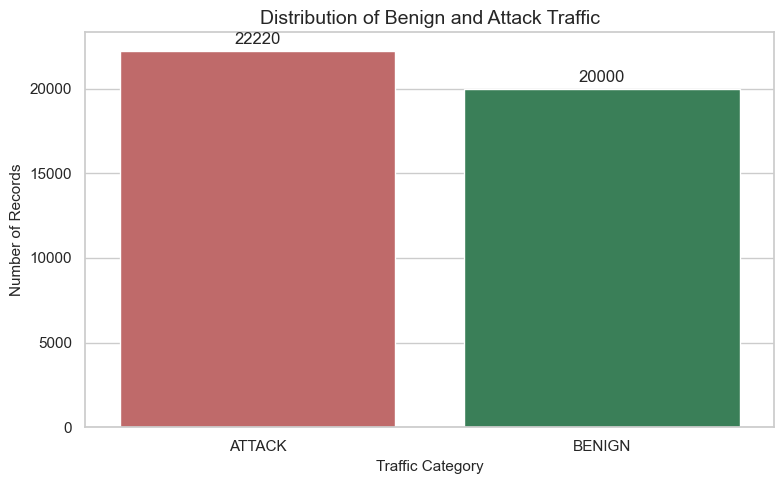

In [7]:
# Visualise Benign vs Attack Traffic
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=traffic_distribution,
    x="Traffic Type",
    y="Record Count",
    hue="Traffic Type",
    palette={"BENIGN": "seagreen", "ATTACK": "indianred"},
    legend=False
)

ax.set_title("Distribution of Benign and Attack Traffic")
ax.set_xlabel("Traffic Category")
ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

### Key Insights

- The dataset contains 22,220 ATTACK records, representing 52.63% of the total.
- BENIGN traffic accounts for 20,000 records, representing 47.37%.
- ATTACK records exceed BENIGN records by 2,220.
- The two traffic categories have relatively similar representation in the selected sample.

### Overall Interpretation

The selected dataset contains a slightly higher proportion of malicious traffic than benign traffic. This attack-enriched distribution should be considered when interpreting model performance and real-world applicability.

### Limitation

This is a stratified, attack-enriched sample and does not represent the natural proportion of malicious traffic in real-world networks.

In [8]:
# Calculate Attack Category Distribution
attack_distribution = (
    df.loc[df["Label"] != "BENIGN", "Label"]
    .value_counts()
    .rename_axis("Attack Type")
    .reset_index(name="Record Count")
)

attack_distribution["Percentage"] = (
    attack_distribution["Record Count"] / len(df) * 100
)

display(attack_distribution)

,Attack Type,Record Count,Percentage
0,DDoS,4000,9.47
1,DoS Hulk,4000,9.47
2,PortScan,4000,9.47
3,FTP-Patator,1500,3.55
4,DoS Slowhttptest,1500,3.55
5,DoS GoldenEye,1500,3.55
6,SSH-Patator,1500,3.55
7,DoS slowloris,1500,3.55
8,Web Attack - Brute Force,1000,2.37
9,Bot,1000,2.37


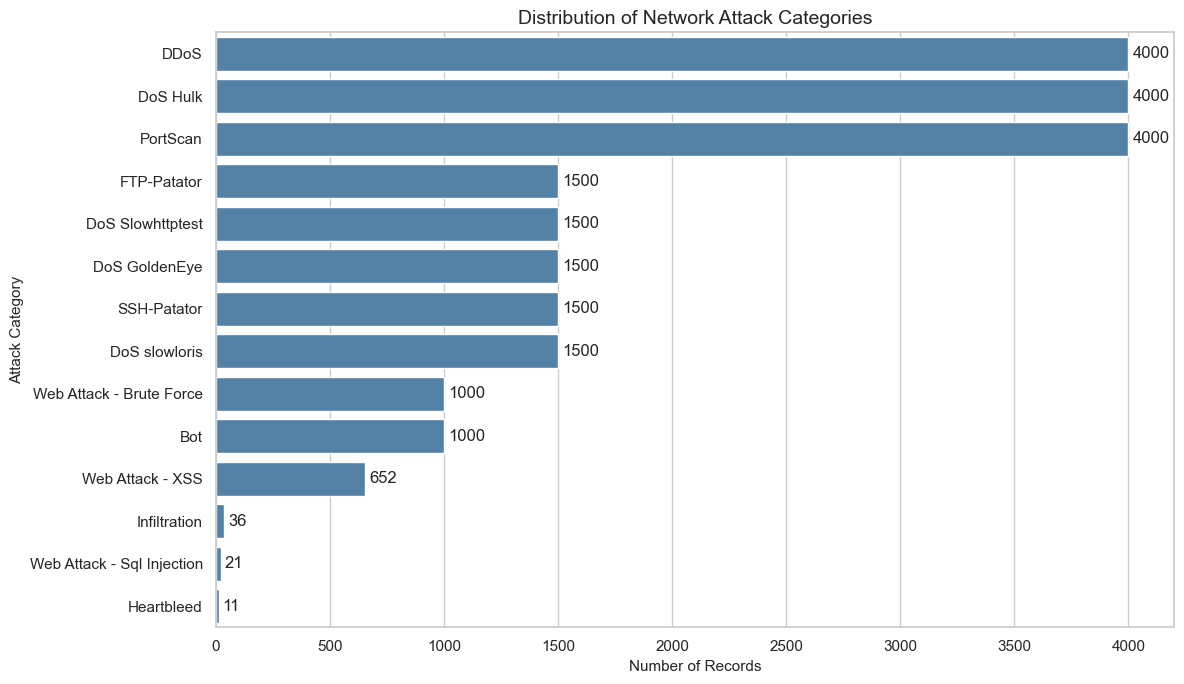

In [9]:
# Visualise Attack Category Distribution
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=attack_distribution,
    x="Record Count",
    y="Attack Type",
    color="steelblue"
)

ax.set_title("Distribution of Network Attack Categories")
ax.set_xlabel("Number of Records")
ax.set_ylabel("Attack Category")

ax.bar_label(ax.containers[0], padding=3, fmt="%d")

plt.tight_layout()
plt.show()

### Key Insights

- DDoS, DoS Hulk and PortScan are the most frequent attack categories, with 4,000 records each.
- FTP-Patator, DoS Slowhttptest, DoS GoldenEye, SSH-Patator and DoS slowloris each contain 1,500 records.
- Web Attack - XSS contains 652 records, while Bot and Web Attack - Brute Force each contain 1,000 records.
- Heartbleed has the lowest frequency, with only 11 records, followed by Web Attack - SQL Injection with 21 records and Infiltration with 36 records.

### Overall Interpretation

The attack categories are unevenly distributed. Several categories have substantially fewer observations, which may affect the reliability of individual attack-class predictions during machine learning evaluation.

In [10]:
# Calculate Day-Wise Traffic Distribution
day_distribution = (
    df["Day"]
    .value_counts()
    .rename_axis("Day")
    .reset_index(name="Record Count")
)

day_distribution["Percentage"] = (
    day_distribution["Record Count"] / len(df) * 100
)

display(day_distribution)

,Day,Record Count,Percentage
0,Friday,13000,30.79
1,Wednesday,12511,29.63
2,Tuesday,7000,16.58
3,Thursday,5709,13.52
4,Monday,4000,9.47


In [11]:
# Analyse Attack Distribution Across Days
day_attack_distribution = pd.crosstab(
    df["Day"],
    df["Label"]
)

display(day_attack_distribution)

Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
Day,,,,,,,,,,,,,,,
Friday,4000,1000,4000,0,0,0,0,0,0,0,4000,0,0,0,0
Monday,4000,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Thursday,4000,0,0,0,0,0,0,0,0,36,0,0,1000,21,652
Tuesday,4000,0,0,0,0,0,0,1500,0,0,0,1500,0,0,0
Wednesday,4000,0,0,1500,4000,1500,1500,0,11,0,0,0,0,0,0


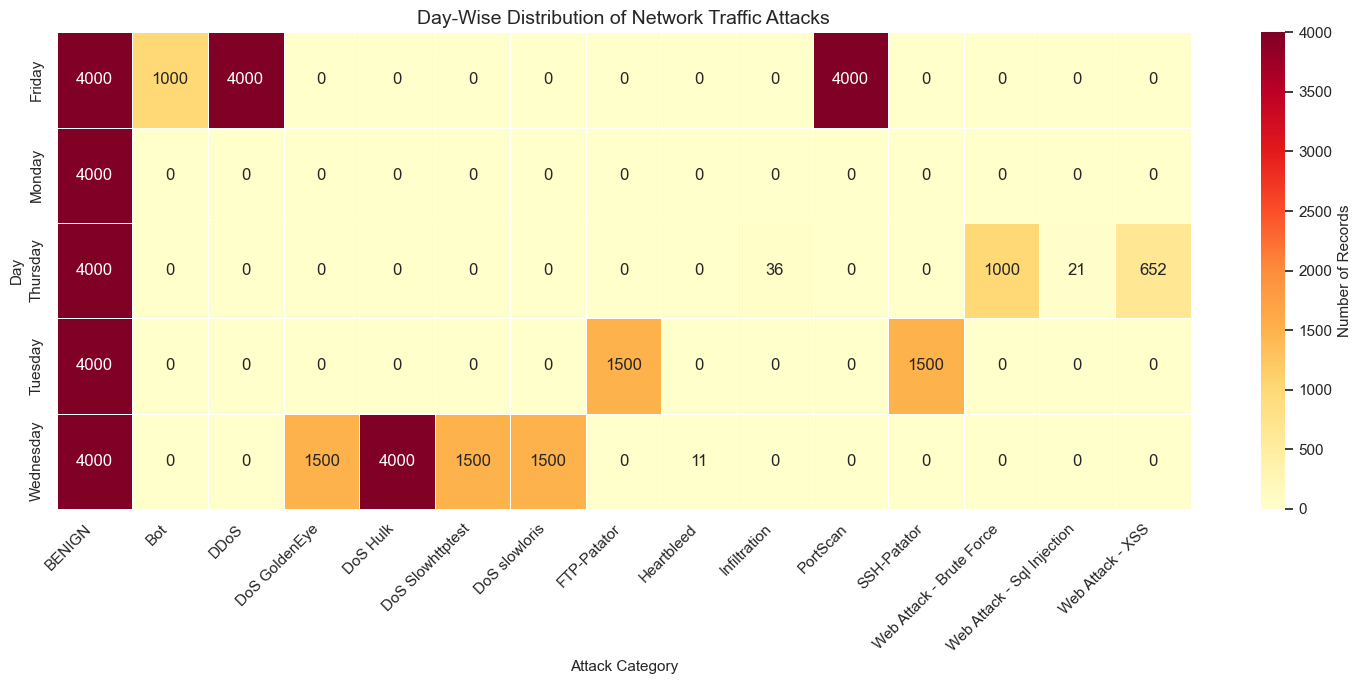

In [12]:
# Visualise Day-Wise Attack Distribution
plt.figure(figsize=(15, 7))

sns.heatmap(
    day_attack_distribution,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Number of Records"}
)

plt.title("Day-Wise Distribution of Network Traffic Attacks")
plt.xlabel("Attack Category")
plt.ylabel("Day")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Key Insights

- Friday recorded the highest attack activity, with 9,000 records.
- Wednesday followed with 8,511 attack records.
- Tuesday recorded 3,000 attacks.
- Thursday recorded 1,709 attacks.
- Monday contained no attack records in the selected sample.
- Attack categories are concentrated on particular days rather than being evenly distributed.

### Overall Interpretation

The distribution reveals significant variation in attack activity across the five days represented in the dataset. Friday and Wednesday account for the largest number of attack records.

### Limitation

These patterns reflect the attack schedule and composition of the selected CIC-IDS2017 sample. They should not be interpreted as general real-world attack trends.

In [13]:
# Extract Hour from Timestamp
df["Hour"] = df["Timestamp"].dt.hour

# Calculate Hour-Wise Traffic Distribution
hourly_distribution = (
    df["Hour"]
    .value_counts()
    .sort_index()
    .rename_axis("Hour")
    .reset_index(name="Record Count")
)

display(hourly_distribution)

,Hour,Record Count
0,1,2134
1,2,7349
2,3,4729
3,4,5779
4,5,88
5,8,143
6,9,5563
7,10,10856
8,11,4332
9,12,1247


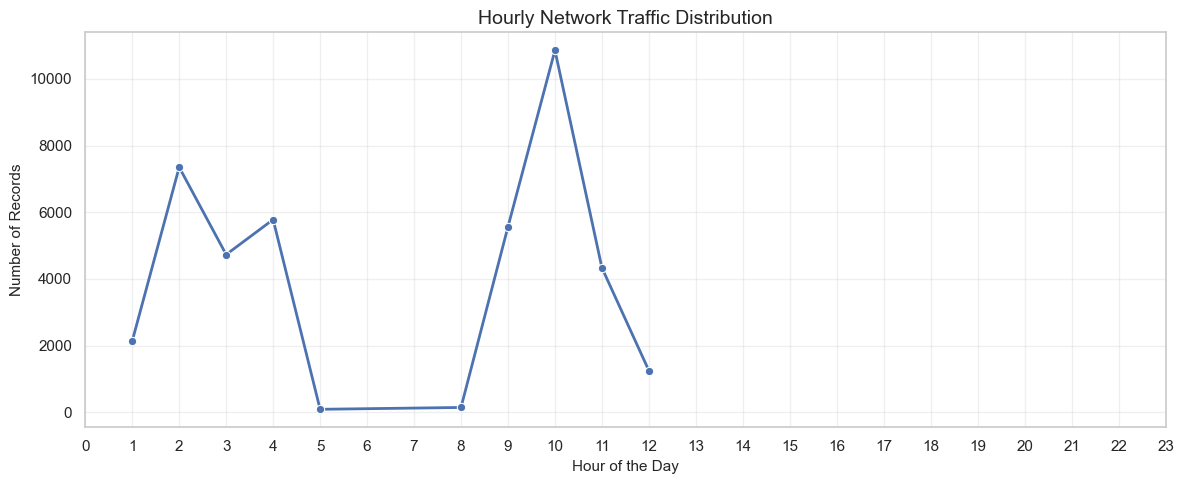

In [14]:
# Visualise Hour-Wise Traffic Distribution
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_distribution,
    x="Hour",
    y="Record Count",
    marker="o",
    linewidth=2
)

plt.title("Hourly Network Traffic Distribution")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Records")

plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights

- The highest overall network traffic volume occurs at 10:00.
- Other prominent traffic peaks appear at 02:00, 04:00 and 09:00.
- Traffic volume decreases considerably during some hours, particularly 05:00 and 08:00.
- The distribution indicates that network traffic volume varies across different hours of the day.

### Overall Interpretation

The hourly distribution helps identify periods of higher and lower network activity. However, this chart combines BENIGN and ATTACK records, so it cannot independently establish when attacks are most frequent.

### Limitation

This analysis describes the selected CIC-IDS2017 sample and does not establish general real-world traffic patterns.

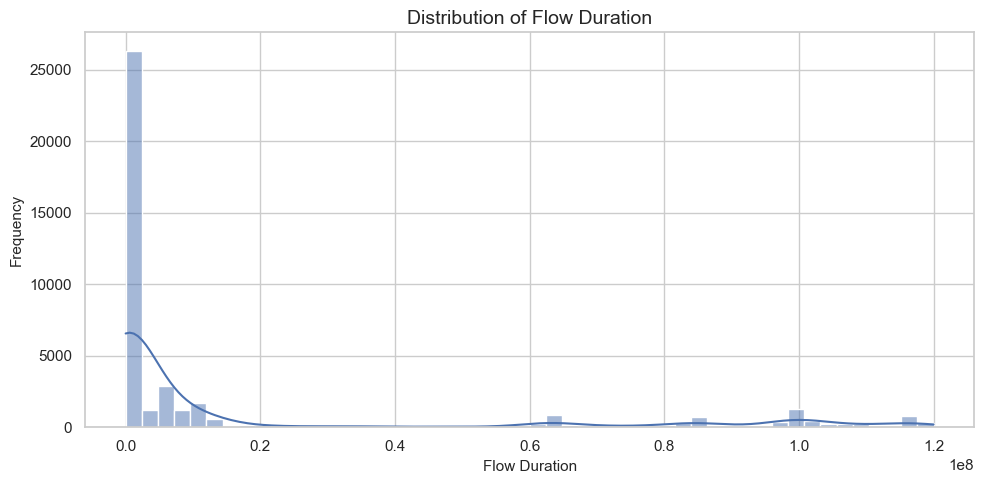

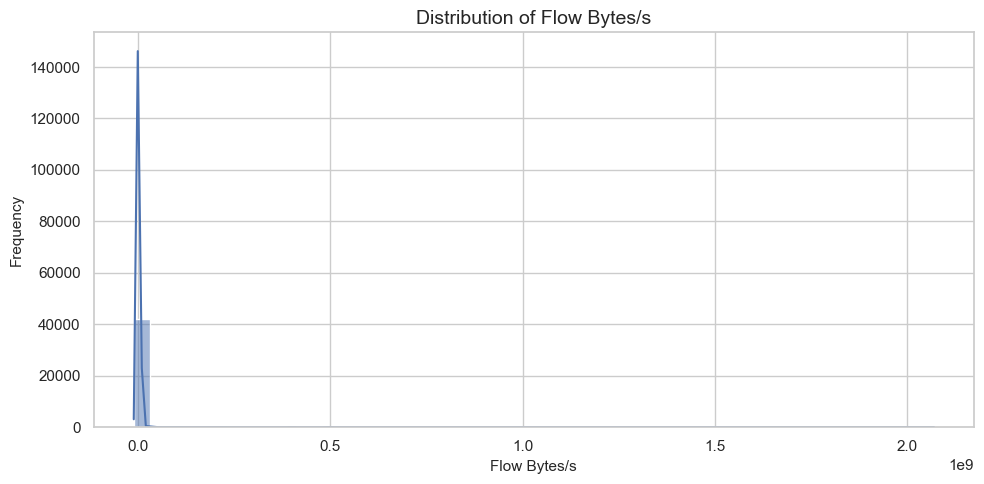

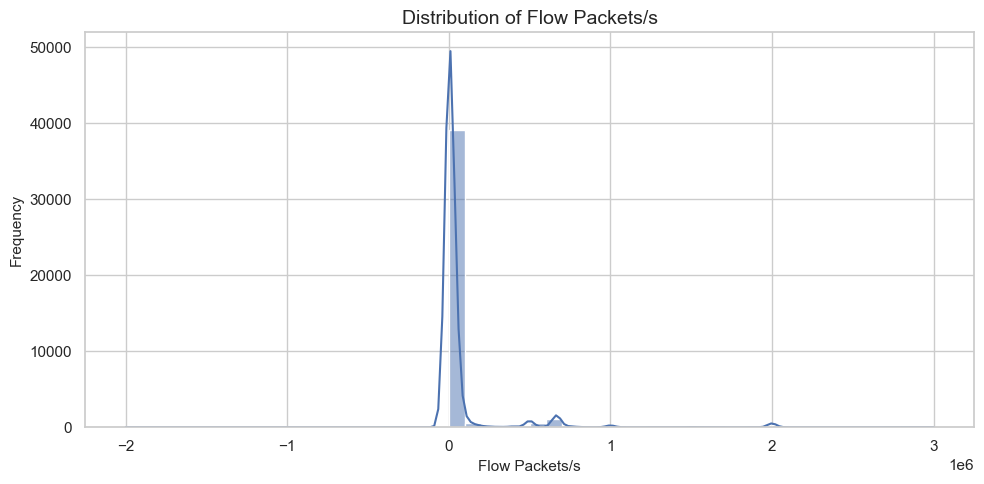

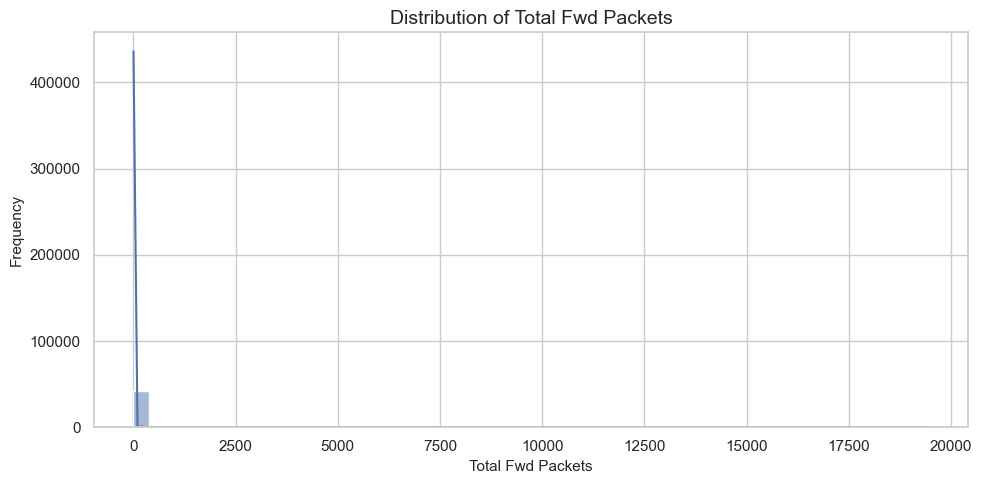

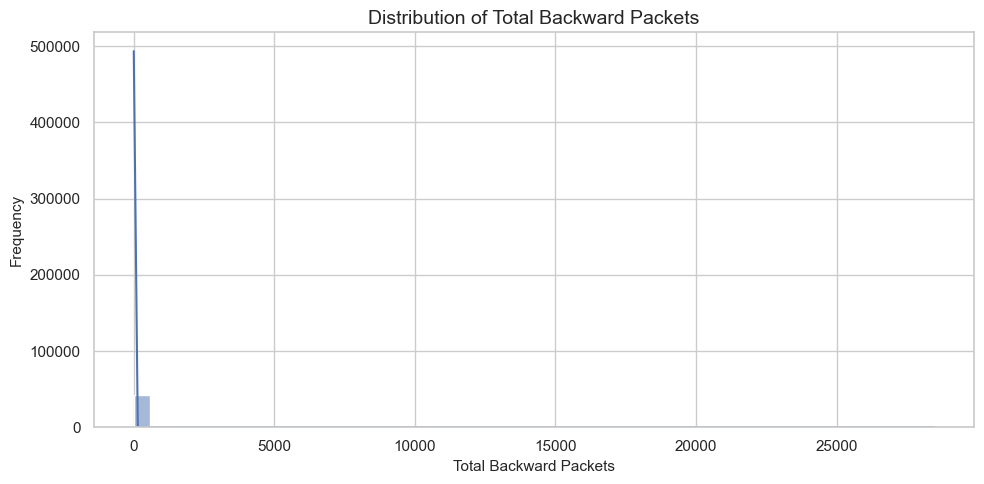

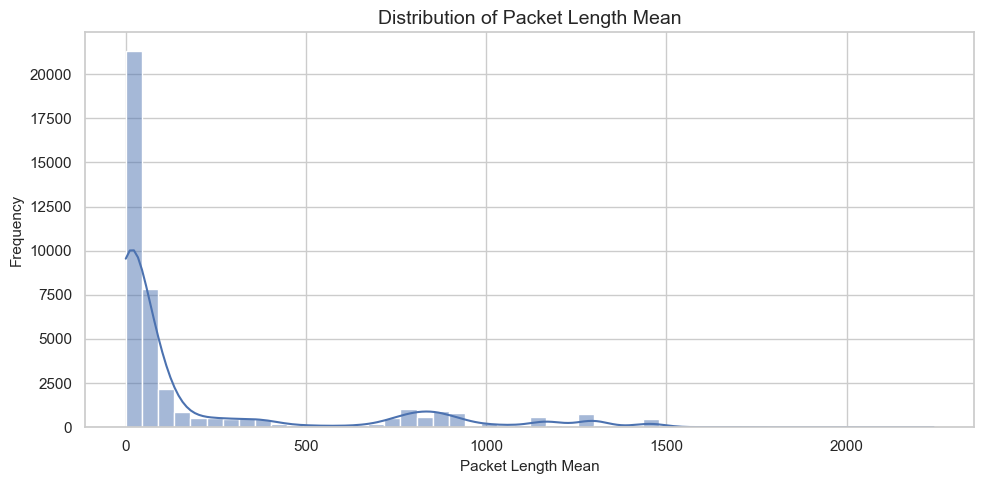

In [15]:
# Select Important Network Traffic Features
selected_features = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Packet Length Mean"
]

# Visualise Feature Distributions
for feature in selected_features:
    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x=feature,
        bins=50,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

### Key Insights

1. **Flow Duration:** Most observations are concentrated at shorter durations, with a long right tail indicating some extremely long network flows.

2. **Flow Bytes/s:** Values are heavily concentrated near zero, with a long tail extending towards very high data transfer rates.

3. **Flow Packets/s:** Most observations are concentrated near zero, while a smaller number of flows have considerably higher packet rates.

4. **Total Fwd Packets:** Most flows contain relatively few forward packets, while a small number contain substantially larger packet counts.

5. **Total Backward Packets:** The distribution is highly concentrated near zero, with a small number of flows containing many backward packets.

6. **Packet Length Mean:** The distribution is concentrated towards lower packet-length values, with observations extending across a wider range.

### Overall Interpretation

The numerical features exhibit highly skewed distributions and varying degrees of extreme values. This supports the need for careful feature analysis and appropriate preprocessing during machine learning.

In [19]:
# Identify Strongly Correlated Feature Pairs

# Calculate correlation matrix using numerical features
correlation_matrix = df.select_dtypes(include=np.number).corr()

# Extract unique feature pairs from the upper triangle
correlation_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

# Rename columns
correlation_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

# Calculate absolute correlation
correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

# Filter strongly correlated feature pairs (threshold >= 0.80)
strong_correlations = (
    correlation_pairs[
        correlation_pairs["Absolute Correlation"] >= 0.80
    ]
    .sort_values("Absolute Correlation", ascending=False)
    .reset_index(drop=True)
)

# Display results
display(strong_correlations)

,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Total Fwd Packets,Subflow Fwd Packets,1.00,1.00
1,Total Backward Packets,Subflow Bwd Packets,1.00,1.00
2,Total Length of Fwd Packets,Subflow Fwd Bytes,1.00,1.00
3,Bwd Packet Length Mean,Avg Bwd Segment Size,1.00,1.00
4,Fwd Packet Length Mean,Avg Fwd Segment Size,1.00,1.00
...,...,...,...,...
116,Fwd Packet Length Mean,Fwd Packet Length Std,0.81,0.81
117,Fwd Packet Length Std,Avg Fwd Segment Size,0.81,0.81
118,Subflow Bwd Bytes,act_data_pkt_fwd,0.81,0.81
119,Total Length of Bwd Packets,act_data_pkt_fwd,0.81,0.81


### Key Insights

- The correlation heatmap reveals strong relationships among several numerical network traffic features.
- A total of 121 feature pairs have an absolute correlation of 0.80 or higher.
- Some feature pairs show perfect positive correlation (1.00), including Total Fwd Packets and Subflow Fwd Packets.
- Strong correlations suggest that certain features may contain overlapping information.
- These relationships should be considered during feature selection and machine learning model development.

### Overall Interpretation

Correlation analysis helps identify relationships and potential redundancy among network traffic features. However, correlation does not establish causation.

In [20]:
# Compare Numerical Features Across Traffic Categories
traffic_feature_summary = (
    df.groupby("Traffic_Type")[selected_features]
    .median()
    .T
)

display(traffic_feature_summary)

Traffic_Type,ATTACK,BENIGN
Flow Duration,3003618.50,30967.00
Flow Bytes/s,141.01,5048.51
Flow Packets/s,4.09,120.87
Total Fwd Packets,3.00,2.00
Total Backward Packets,1.00,2.00
Packet Length Mean,6.00,58.40


In [21]:
# Encode Binary Traffic Classification

df["Binary_Label"] = df["Traffic_Type"].map({
    "BENIGN": 0,
    "ATTACK": 1
})


# Calculate Feature Correlation with Traffic Classification

excluded_features = [
    "Protocol",
    "Source Port",
    "Destination Port"
]

numeric_features = (
    df.select_dtypes(include=["int64", "float64"])
    .drop(columns=excluded_features, errors="ignore")
)

feature_correlations = (
    numeric_features
    .corr()["Binary_Label"]
    .drop("Binary_Label")
    .sort_values(key=abs, ascending=False)
)

display(
    feature_correlations.to_frame(
        name="Correlation with Attack"
    )
)

,Correlation with Attack
Bwd Packet Length Min,-0.44
Min Packet Length,-0.35
PSH Flag Count,0.33
Bwd Packet Length Std,0.32
Bwd Packet Length Max,0.31
Packet Length Std,0.30
Bwd Packet Length Mean,0.29
Avg Bwd Segment Size,0.29
Packet Length Variance,0.29
Max Packet Length,0.29


### Key Insights

- Bwd Packet Length Min shows the strongest negative correlation with binary attack classification, with a coefficient of -0.44.
- Min Packet Length also shows a negative correlation of -0.35.
- PSH Flag Count has a positive correlation of 0.33.
- Bwd Packet Length Std shows a positive correlation of 0.32.
- Bwd Packet Length Max has a positive correlation of 0.31.
- Most other visible features have relatively weak correlations with the binary attack label.

### Overall Interpretation

These results indicate that individual numerical features have varying degrees of linear association with attack classification. Correlation alone is not sufficient to determine predictive importance or establish causation. These relationships can provide useful insights for further feature analysis and model development.

In [22]:
# Analyse Protocol Distribution by Traffic Category
protocol_distribution = pd.crosstab(
    df["Protocol"],
    df["Traffic_Type"],
    normalize="index"
) * 100

display(protocol_distribution)

Traffic_Type,ATTACK,BENIGN
Protocol,,
0.00,0.00,100.00
6.00,66.55,33.45
17.00,0.00,100.00


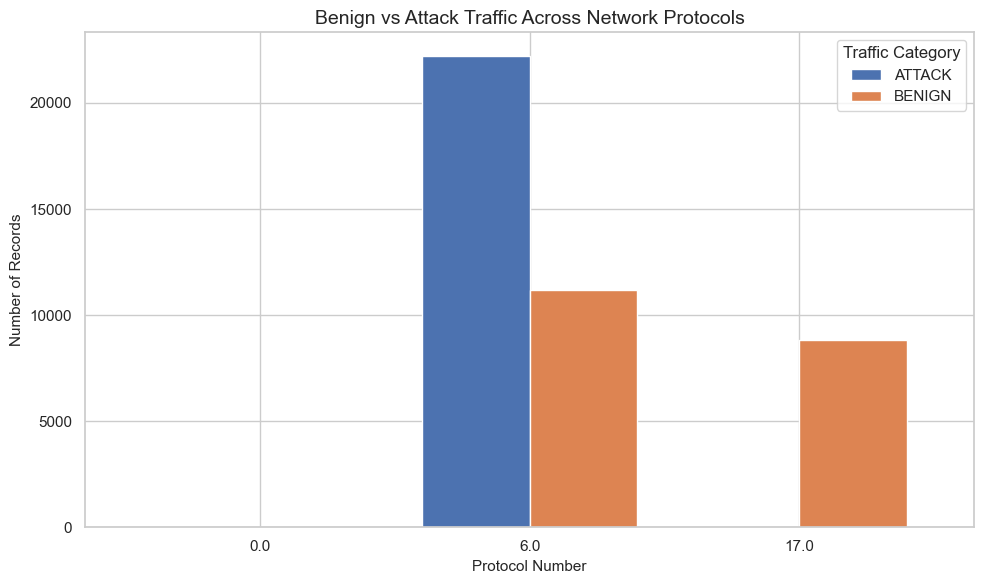

In [23]:
# Visualise Protocol Distribution by Traffic Category
protocol_plot = pd.crosstab(
    df["Protocol"],
    df["Traffic_Type"]
)

protocol_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Benign vs Attack Traffic Across Network Protocols")
plt.xlabel("Protocol Number")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(title="Traffic Category")

plt.tight_layout()
plt.show()

### Key Insight

- All ATTACK records (22,220) in the selected dataset use Protocol 6 (TCP).
- BENIGN traffic appears across Protocol 0, Protocol 6 (TCP), and Protocol 17 (UDP).
- This indicates a difference in protocol distribution between BENIGN and ATTACK traffic in this sample.
- This pattern is specific to the selected CIC-IDS2017 sample and should not be generalized to all real-world network attacks.

In [24]:
# Analyse Most Frequently Used Destination Ports
port_distribution = (
    df["Destination Port"]
    .value_counts()
    .head(15)
    .rename_axis("Destination Port")
    .reset_index(name="Record Count")
)

display(port_distribution)

,Destination Port,Record Count
0,80.00,16290
1,53.00,8430
2,443.00,4368
3,22.00,1621
4,21.00,1549
5,8080.00,668
6,123.00,228
7,137.00,74
8,389.00,53
9,88.00,52


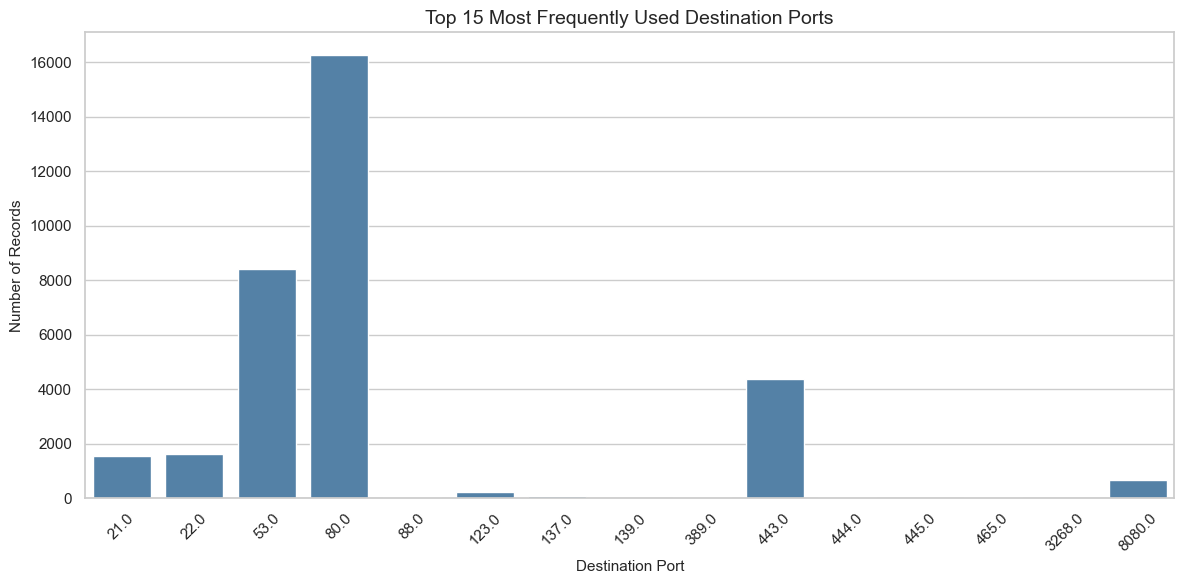

In [25]:
# Visualise Top 15 Destination Ports
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=port_distribution,
    x="Destination Port",
    y="Record Count",
    color="steelblue"
)

ax.set_title("Top 15 Most Frequently Used Destination Ports")
ax.set_xlabel("Destination Port")
ax.set_ylabel("Number of Records")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Key Insights

- Destination Port 80 has the highest traffic volume, with 16,290 records.
- Port 53 follows with 8,430 records, followed by Port 443 with 4,368 records.
- Ports 21 and 22 show considerably lower traffic volumes, with 1,549 and 1,621 records, respectively.
- The distribution indicates that network traffic is concentrated on a small number of destination ports.
- High traffic frequency does not necessarily indicate malicious activity. Further analysis of attack counts and attack rates by port is required to assess security risk.

In [26]:
# Analyse Destination Ports by Traffic Category
port_attack_distribution = (
    df.groupby(["Destination Port", "Traffic_Type"])
    .size()
    .unstack(fill_value=0)
)

# Select Top 15 Ports by Total Traffic
port_attack_distribution["Total"] = (
    port_attack_distribution.sum(axis=1)
)

top_ports = (
    port_attack_distribution
    .nlargest(15, "Total")
    .drop(columns="Total")
    .sort_values("ATTACK", ascending=False)
)

display(top_ports)

Traffic_Type,ATTACK,BENIGN
Destination Port,,
80.00,14184,2106
22.00,1510,111
21.00,1505,44
8080.00,650,18
444.00,51,0
88.00,6,46
53.00,5,8425
139.00,5,24
465.00,5,34


In [27]:
# Analyse Attack Frequency by Day and Hour
attack_time_distribution = (
    df[df["Traffic_Type"] == "ATTACK"]
    .pivot_table(
        index="Day",
        columns="Hour",
        values="Label",
        aggfunc="count",
        fill_value=0
    )
)

display(attack_time_distribution)

Hour,1,2,3,4,9,10,11,12
Day,,,,,,,,
Friday,6,3501,1254,3239,0,730,135,135
Thursday,0,18,18,0,997,676,0,0
Tuesday,0,1278,222,0,991,509,0,0
Wednesday,0,1,11,0,836,5988,1675,0


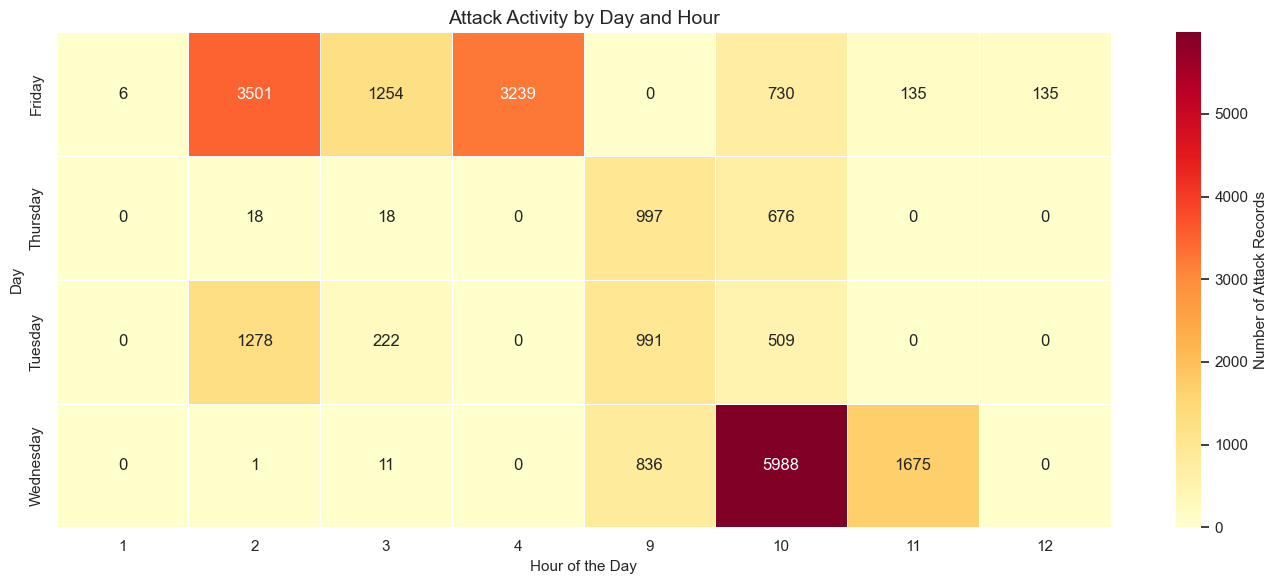

In [28]:
# Visualise Attack Frequency by Day and Hour
plt.figure(figsize=(14, 6))

sns.heatmap(
    attack_time_distribution,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Number of Attack Records"}
)

plt.title("Attack Activity by Day and Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Day")

plt.tight_layout()
plt.show()

### Key Insights

- Wednesday at 10:00 recorded the highest attack activity, with 5,988 records.
- Friday showed substantial attack activity at 02:00 (3,501) and 04:00 (3,239).
- Wednesday also recorded 1,675 attacks at 11:00.
- Tuesday and Thursday showed comparatively lower attack activity across the displayed hours.
- Monday had no recorded attacks in the selected dataset.

### Overall Interpretation

Attack activity is concentrated in particular day-and-hour combinations rather than being evenly distributed. These patterns can help identify periods that deserve closer monitoring.

### Limitation

These observations describe the selected CIC-IDS2017 sample and should not be treated as universal network attack patterns.

In [29]:
# Detect Outliers Using the IQR Method
outlier_summary = []

for feature in selected_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": feature,
        "Outlier Count": outlier_count,
        "Outlier Percentage": (outlier_count / len(df)) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Feature,Outlier Count,Outlier Percentage
0,Flow Duration,7872,18.65
1,Flow Bytes/s,6467,15.32
2,Flow Packets/s,4014,9.51
3,Total Fwd Packets,3640,8.62
4,Total Backward Packets,3704,8.77
5,Packet Length Mean,8119,19.23


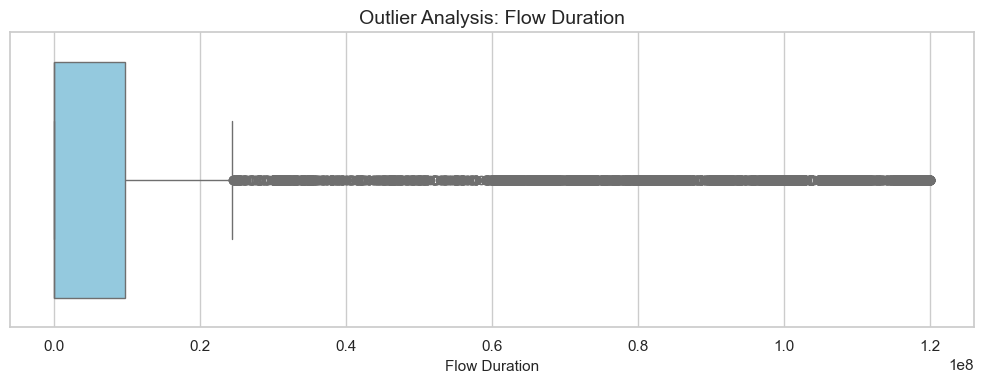

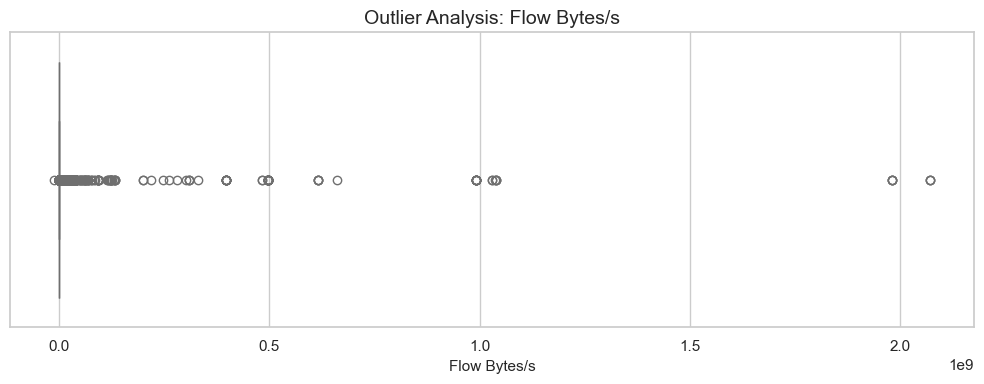

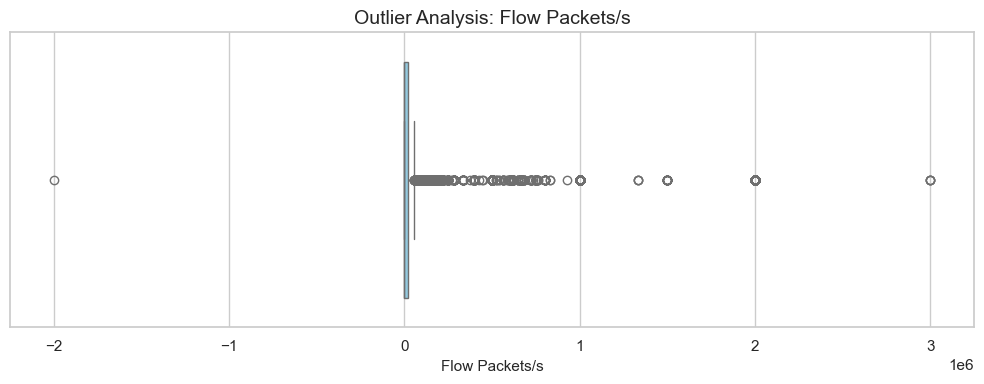

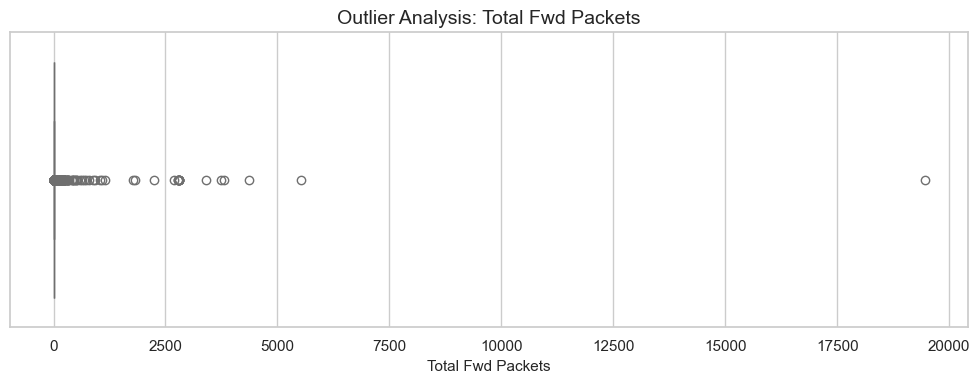

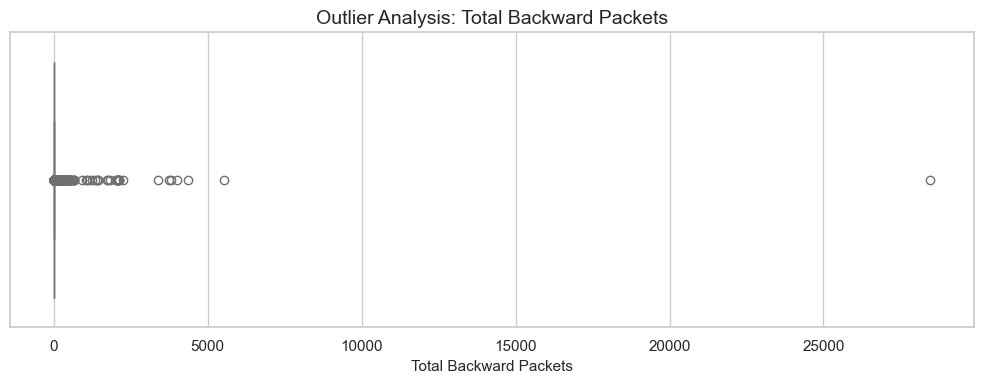

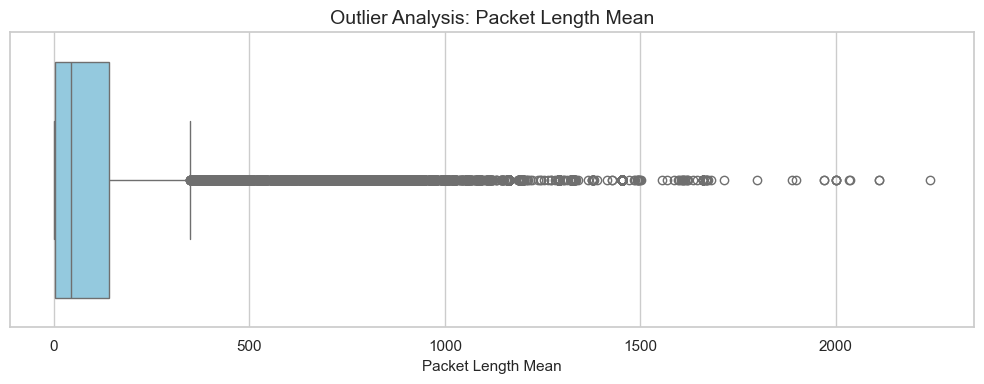

In [30]:
# Visualise Outliers in Network Traffic Features
for feature in selected_features:
    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df[feature],
        color="skyblue"
    )

    plt.title(f"Outlier Analysis: {feature}")
    plt.xlabel(feature)

    plt.tight_layout()
    plt.show()

### Key Insights

The Interquartile Range (IQR) method was used to identify potential outliers in six numerical network traffic features.

| Feature | Outlier Percentage |
|---|---:|
| Packet Length Mean | 19.23% |
| Flow Duration | 18.65% |
| Flow Bytes/s | 15.32% |
| Flow Packets/s | 9.51% |
| Total Backward Packets | 8.77% |
| Total Fwd Packets | 8.62% |

### Overall Interpretation

- Packet Length Mean has the highest outlier percentage at 19.23%.
- Flow Duration also contains a substantial proportion of potential outliers at 18.65%.
- Total Fwd Packets has the lowest outlier percentage among the six selected features at 8.62%.
- The distributions indicate considerable variation in network traffic characteristics.

### Conclusion

Outliers were retained rather than automatically removed because unusually high or low network traffic values may represent meaningful network behaviour, including potentially suspicious activity.

The IQR method identifies statistical outliers, but an outlier is not necessarily an error or a malicious event.

In [31]:
# Analyse Skewness and Kurtosis
distribution_analysis = df[selected_features].agg(
    ["mean", "median", "std", "skew", "kurt"]
).T

display(distribution_analysis)

,mean,median,std,skew,kurt
Flow Duration,17965698.70,78031.50,34937006.94,1.83,1.69
Flow Bytes/s,1819187.12,1275.21,36394856.76,38.59,1813.25
Flow Packets/s,59796.52,57.54,230184.45,6.15,44.84
Total Fwd Packets,7.46,2.00,116.38,120.07,18763.63
Total Backward Packets,7.07,2.00,153.50,154.84,28089.62
Packet Length Mean,209.87,43.00,367.57,1.92,2.52


In [32]:
# Compare Network Features Across Attack Categories
attack_feature_profile = (
    df.groupby("Label")[selected_features]
    .median()
    .sort_values("Flow Duration", ascending=False)
)

display(attack_feature_profile)

,Flow Duration,Flow Bytes/s,Flow Packets/s,Total Fwd Packets,Total Backward Packets,Packet Length Mean
Label,,,,,,
Heartbleed,119261118.00,66172.23,40.84,2792.00,2069.00,1620.05
Infiltration,93188869.00,173.35,1.00,26.00,26.00,146.71
DoS Hulk,85012792.50,121.18,0.16,6.00,6.00,796.87
DoS slowloris,77154322.50,0.21,0.18,3.00,2.00,4.80
DoS Slowhttptest,63114983.50,0.00,0.11,7.00,0.00,0.00
DoS GoldenEye,11571877.50,655.64,1.00,7.00,5.00,555.54
SSH-Patator,10782525.00,341.58,4.95,19.00,31.00,84.88
FTP-Patator,7894233.50,37.25,3.03,9.00,15.00,11.26
Web Attack - Brute Force,5534575.00,0.00,0.74,3.00,1.00,0.00


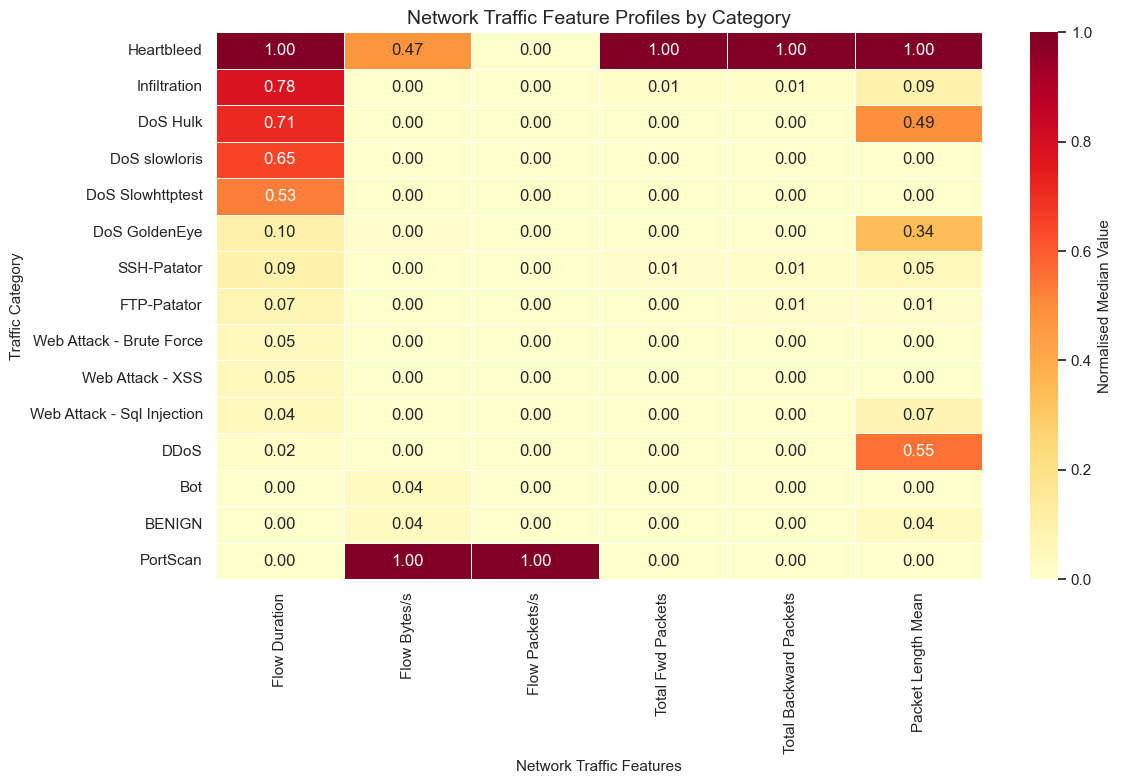

In [33]:
# Normalise Median Feature Values Across Traffic Categories
feature_profile_normalised = (
    attack_feature_profile
    .subtract(attack_feature_profile.min())
    .divide(
        attack_feature_profile.max() - attack_feature_profile.min()
    )
    .fillna(0)
)

# Visualise Attack Feature Profiles
plt.figure(figsize=(12, 8))

sns.heatmap(
    feature_profile_normalised,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Normalised Median Value"}
)

plt.title("Network Traffic Feature Profiles by Category")
plt.xlabel("Network Traffic Features")
plt.ylabel("Traffic Category")

plt.tight_layout()
plt.show()

### Key Insights

- Heartbleed shows the highest normalised median Flow Duration (1.00) among the displayed categories.
- PortScan records the highest normalised median Flow Bytes/s (1.00) and Flow Packets/s (1.00).
- DoS Hulk and Infiltration show relatively high normalised median Flow Duration values of 0.71 and 0.78, respectively.
- DDoS has a normalised median Packet Length Mean of 0.55.
- Different attack categories exhibit different numerical feature profiles.

### Overall Interpretation

The heatmap highlights variations in network traffic characteristics across attack categories. These differences may help identify useful features for further statistical analysis and machine learning.

### Limitation

The values are normalised separately for each feature. They should not be interpreted as raw measurements or used to compare the absolute magnitude of different features.

In [34]:
# Calculate Attack Rate by Destination Port
port_risk_analysis = (
    df.groupby("Destination Port")
    .agg(
        Total_Records=("Binary_Label", "count"),
        Attack_Records=("Binary_Label", "sum"),
        Attack_Rate=("Binary_Label", "mean")
    )
    .reset_index()
)

# Convert Attack Rate to Percentage
port_risk_analysis["Attack_Rate"] *= 100

# Exclude Ports with Very Few Observations
port_risk_analysis = (
    port_risk_analysis[
        port_risk_analysis["Total_Records"] >= 100
    ]
    .sort_values("Attack_Rate", ascending=False)
    .reset_index(drop=True)
)

display(port_risk_analysis.head(15))

,Destination Port,Total_Records,Attack_Records,Attack_Rate
0,8080.00,668,650,97.31
1,21.00,1549,1505,97.16
2,22.00,1621,1510,93.15
3,80.00,16290,14184,87.07
4,53.00,8430,5,0.06
5,443.00,4368,2,0.05
6,123.00,228,0,0.00


In [35]:
# Compare Network Traffic Volume by Category
traffic_volume_analysis = (
    df.groupby("Traffic_Type")["Flow Bytes/s"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

display(traffic_volume_analysis)

,count,mean,median,max
Traffic_Type,,,,
ATTACK,22220,1705090.61,141.01,1980000000.00
BENIGN,20000,1945948.35,5048.51,2071000000.00


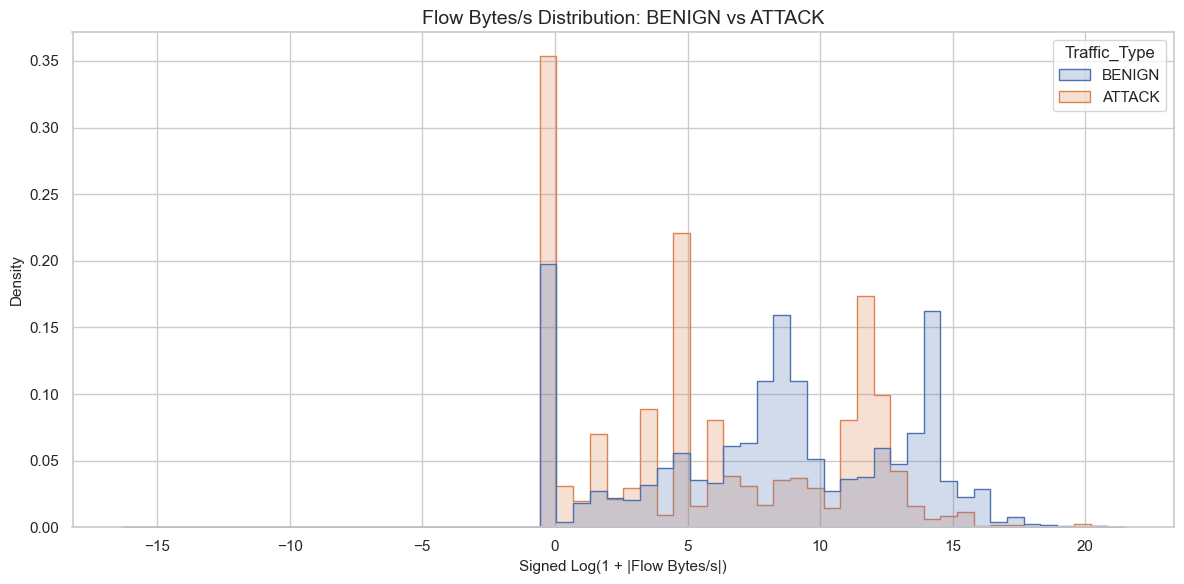

In [36]:
# Compare Flow Bytes/s Distributions

# Prepare data
flow_bytes_plot = df[
    ["Flow Bytes/s", "Traffic_Type"]
].copy()

# Apply signed log transformation
flow_bytes_plot["Signed_Log_Flow_Bytes"] = (
    np.sign(flow_bytes_plot["Flow Bytes/s"])
    * np.log1p(np.abs(flow_bytes_plot["Flow Bytes/s"]))
)

# Create histogram
plt.figure(figsize=(12, 6))

sns.histplot(
    data=flow_bytes_plot,
    x="Signed_Log_Flow_Bytes",
    hue="Traffic_Type",
    bins=60,
    element="step",
    stat="density",
    common_norm=False
)

# Chart formatting
plt.title(
    "Flow Bytes/s Distribution: BENIGN vs ATTACK"
)

plt.xlabel("Signed Log(1 + |Flow Bytes/s|)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

### Key Insight

- Both BENIGN and ATTACK traffic show highly skewed Flow Bytes/s distributions.
- ATTACK traffic has a mean of 1,705,090.61 and a median of 141.01.
- BENIGN traffic has a mean of 1,945,948.35 and a median of 5,048.51.
- The large differences between mean and median indicate the influence of extreme values.
- Therefore, the mean alone does not adequately represent typical network traffic volume.

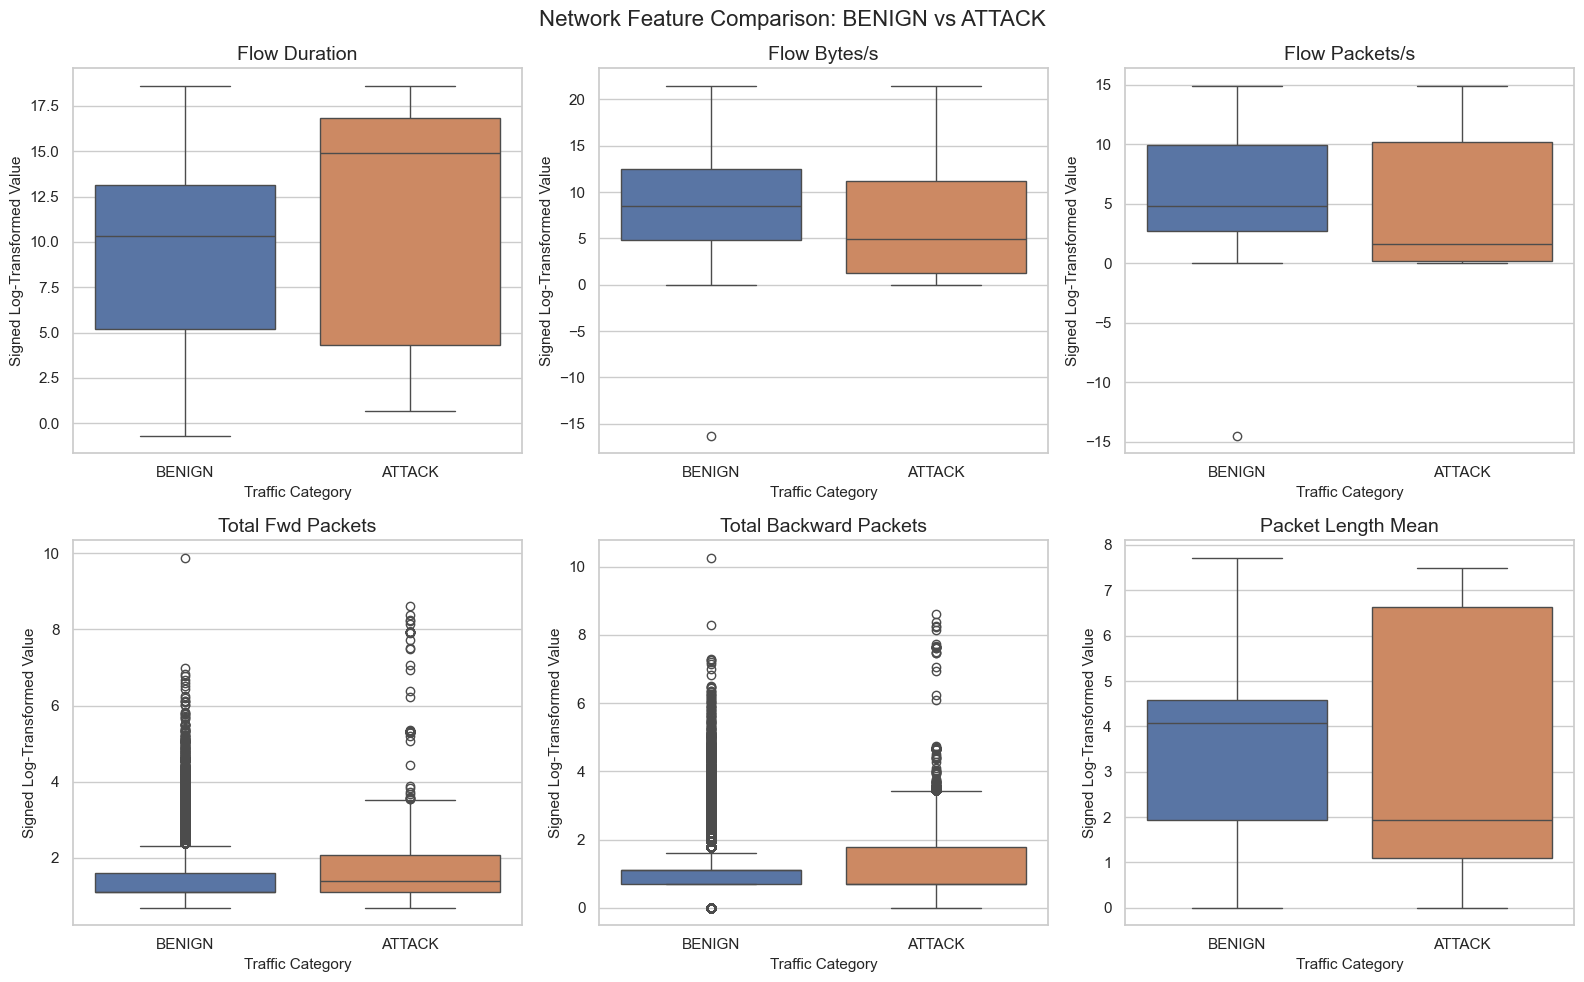

In [37]:
# Prepare Network Features for Comparison

feature_comparison = df[
    selected_features + ["Traffic_Type"]
].copy()


# Apply Signed Log Transformation
# Handles both negative and positive values safely

feature_comparison[selected_features] = (
    np.sign(feature_comparison[selected_features])
    * np.log1p(np.abs(feature_comparison[selected_features]))
)


# Visualise Feature Distributions by Traffic Category

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for feature, ax in zip(selected_features, axes.flatten()):

    sns.boxplot(
        data=feature_comparison,
        x="Traffic_Type",
        y=feature,
        hue="Traffic_Type",
        legend=False,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Traffic Category")
    ax.set_ylabel("Signed Log-Transformed Value")


fig.suptitle(
    "Network Feature Comparison: BENIGN vs ATTACK",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Key Insights

- ATTACK traffic shows a higher median Flow Duration than BENIGN traffic.
- BENIGN traffic has a higher median Flow Bytes/s in this sample.
- Flow Packets/s distributions overlap considerably between the two traffic categories.
- ATTACK traffic shows higher median values for Total Fwd Packets and Total Backward Packets.
- Packet Length Mean has a lower median and wider interquartile range for ATTACK traffic.
- Several features contain outliers, indicating substantial variation in network flow characteristics.

### Overall Interpretation

The boxplots reveal differences in the distributions of several network features between BENIGN and ATTACK traffic. However, no single feature should be considered sufficient for identifying malicious traffic. These patterns support further investigation through statistical analysis and machine learning.

In [38]:
# Generate EDA Summary

eda_summary = {
    "Total Records": len(df),
    "Original Dataset Columns": 77,
    "Derived EDA Columns": 3,
    "Total EDA DataFrame Columns": df.shape[1],
    "Unique Attack Categories": df["Label"].nunique() - 1,
    "Days Covered": df["Day"].nunique(),
    "Benign Records": (df["Traffic_Type"] == "BENIGN").sum(),
    "Attack Records": (df["Traffic_Type"] == "ATTACK").sum(),
    "Highest Frequency Attack": attack_distribution.iloc[0]["Attack Type"],
    "Highest Frequency Attack Count": attack_distribution.iloc[0]["Record Count"],
    "Lowest Frequency Attack": attack_distribution.iloc[-1]["Attack Type"],
    "Lowest Frequency Attack Count": attack_distribution.iloc[-1]["Record Count"],
    "Feature with Highest Outlier Percentage": outlier_summary.loc[
        outlier_summary["Outlier Percentage"].idxmax(), "Feature"
    ],
    "Highest Outlier Percentage": round(
        outlier_summary["Outlier Percentage"].max(), 2
    )
}

eda_summary_df = pd.DataFrame(
    eda_summary.items(),
    columns=["EDA Metric", "Result"]
)

display(eda_summary_df)

,EDA Metric,Result
0,Total Records,42220
1,Original Dataset Columns,77
2,Derived EDA Columns,3
3,Total EDA DataFrame Columns,80
4,Unique Attack Categories,14
5,Days Covered,5
6,Benign Records,20000
7,Attack Records,22220
8,Highest Frequency Attack,DDoS
9,Highest Frequency Attack Count,4000


In [39]:
# Export EDA Summary
from pathlib import Path

report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)

eda_summary_path = report_dir / "eda_summary.csv"

eda_summary_df.to_csv(
    eda_summary_path,
    index=False
)

In [40]:
import numpy as np

df["Traffic_Type"] = np.where(
    df["Label"] == "BENIGN",
    "BENIGN",
    "ATTACK"
)

In [41]:
from scipy.stats import mannwhitneyu

# Compare BENIGN and ATTACK traffic
features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Packet Length Mean"
]

for feature in features:
    benign = df.loc[df["Traffic_Type"] == "BENIGN", feature].dropna()
    attack = df.loc[df["Traffic_Type"] == "ATTACK", feature].dropna()

    statistic, p_value = mannwhitneyu(
        benign,
        attack,
        alternative="two-sided"
    )

    print(f"\nFeature: {feature}")
    print(f"Mann-Whitney U Statistic: {statistic:.2f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Result: Statistically significant difference")
    else:
        print("Result: No statistically significant difference")


Feature: Flow Duration
Mann-Whitney U Statistic: 174941560.00
P-value: 0.000000
Result: Statistically significant difference

Feature: Total Fwd Packets
Mann-Whitney U Statistic: 186131126.00
P-value: 0.000000
Result: Statistically significant difference

Feature: Packet Length Mean
Mann-Whitney U Statistic: 245287897.00
P-value: 0.000000
Result: Statistically significant difference


### Mann-Whitney U Test Findings

The Mann-Whitney U test was performed to compare BENIGN and ATTACK network traffic across three numerical features.

Features tested:
1. Flow Duration
2. Total Fwd Packets
3. Packet Length Mean

All three features showed statistically significant differences between BENIGN and ATTACK traffic (p < 0.001).

**Conclusion:** The distributions of these three network traffic features differ significantly between the two traffic categories.

In [42]:
from scipy.stats import f_oneway

# Select attack categories
attack_data = df[df["Label"] != "BENIGN"]

# Group Flow Duration by attack category
groups = [
    group["Flow Duration"].dropna()
    for _, group in attack_data.groupby("Label")
]

# Perform One-Way ANOVA
f_statistic, p_value = f_oneway(*groups)

print("One-Way ANOVA Results")
print("----------------------")
print(f"F-Statistic: {f_statistic:.4f}")
print(f"P-value: {p_value:.10f}")

if p_value < 0.05:
    print("Result: Significant difference between attack categories")
else:
    print("Result: No significant difference between attack categories")

One-Way ANOVA Results
----------------------
F-Statistic: 1097.8993
P-value: 0.0000000000
Result: Significant difference between attack categories


### One-Way ANOVA Findings

One-Way ANOVA was performed to compare Flow Duration across different attack categories.

- F-statistic: 1097.8993
- P-value: < 0.001
- Result: Statistically significant difference.

**Conclusion:** The mean Flow Duration differs significantly across at least some attack categories.

In [43]:
from scipy.stats import levene

attack_data = df[df["Label"] != "BENIGN"].copy()

groups = [
    group["Flow Duration"].dropna()
    for _, group in attack_data.groupby("Label")
]

statistic, p_value = levene(*groups, center="median")

print("Levene's Test")
print("--------------------")
print(f"Statistic: {statistic:.4f}")
print(f"P-value: {p_value:.10f}")

if p_value < 0.05:
    print("Result: Equal variance assumption is violated.")
else:
    print("Result: No significant evidence of unequal variances.")

Levene's Test
--------------------
Statistic: 780.0503
P-value: 0.0000000000
Result: Equal variance assumption is violated.


In [ ]:
%pip install pingouin

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ----------------------------- ---------- 1.0/1.4 MB 7.6 MB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 7.6 MB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 7.6 MB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 7.6 MB/s eta 0:00:01
   ------------------------------------ --- 1.3/1.4 MB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 1.0 MB/s  0:00:01

   ---------- ----------------------------- 1/4 [xarray]
   ---------- ----------------------------- 1/4 [xarray]
   ---------- ----------------------------- 1/4 [xarray]
   ---------- ----------------------------- 1/4 [xarray]
   ---------- ----------------------------- 1/4 [xarray]
   ---------- ----------------------------- 1/4 [xarray]
   ---------- ----------------------------- 1/4 [xarray]



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
import pingouin as pg

attack_data = df[df["Label"] != "BENIGN"].copy()

welch_result = pg.welch_anova(
    data=attack_data,
    dv="Flow Duration",
    between="Label"
)

display(welch_result)

,Source,ddof1,ddof2,F,p_unc,np2
0,Label,13,350.82,1343.51,0.00,0.39


In [45]:
games_howell = pg.pairwise_gameshowell(
    data=attack_data,
    dv="Flow Duration",
    between="Label"
)

display(games_howell)

,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,Bot,DDoS,353214.84,17482740.45,-17129525.61,503296.45,-34.03,4119.90,0.00,-0.61
1,Bot,DoS GoldenEye,353214.84,22276198.01,-21922983.17,681021.88,-32.19,1524.13,0.00,-1.08
2,Bot,DoS Hulk,353214.84,57883626.35,-57530411.51,728523.62,-78.97,4057.00,0.00,-1.40
3,Bot,DoS Slowhttptest,353214.84,56920630.68,-56567415.84,948560.22,-59.64,1511.92,0.00,-1.99
4,Bot,DoS slowloris,353214.84,55622121.32,-55268906.48,1280632.74,-43.16,1506.08,0.00,-1.44
5,Bot,FTP-Patator,353214.84,4592334.95,-4239120.11,132728.98,-31.94,2199.19,0.00,-1.14
6,Bot,Heartbleed,353214.84,110679707.55,-110326492.71,8596230.79,-12.83,10.00,0.00,-31.98
7,Bot,Infiltration,353214.84,78407720.50,-78054505.66,6733060.04,-11.59,35.01,0.00,-10.16
8,Bot,PortScan,353214.84,70929.72,282285.12,69174.93,4.08,1510.52,0.00,0.15
9,Bot,SSH-Patator,353214.84,6312492.97,-5959278.13,171304.74,-34.79,1921.80,0.00,-1.20


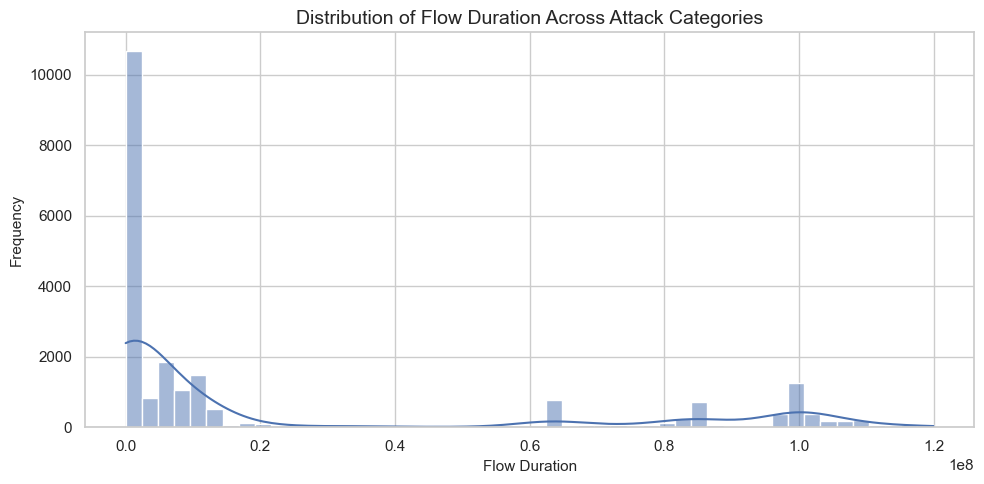

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=attack_data,
    x="Flow Duration",
    bins=50,
    kde=True
)

plt.title("Distribution of Flow Duration Across Attack Categories")
plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Statistical Analysis and Hypothesis Testing

**1. Mann-Whitney U Test**

The Mann-Whitney U test was conducted to compare BENIGN and ATTACK traffic for:
- Flow Duration
- Total Fwd Packets
- Packet Length Mean

All three comparisons showed statistically significant differences (p < 0.001).

**2. One-Way ANOVA**

One-Way ANOVA was conducted to examine differences in Flow Duration across attack categories. The result was statistically significant (p < 0.001).

**3. Levene's Test**

Levene's test returned a statistic of 780.0503 (p < 0.001), indicating that the equal variance assumption was violated.

**4. Welch's ANOVA**

Welch's ANOVA was used as an alternative because it accommodates unequal group variances. The result indicated statistically significant differences in mean Flow Duration across attack categories (p < 0.001).

**5. Games-Howell Post-Hoc Test**

Games-Howell pairwise comparisons were conducted to identify which attack categories differed significantly.

**6. Normality Assessment**

The Flow Duration distribution was visually examined using a histogram to assess its shape, skewness, and potential deviations from normality. No formal statistical normality test was performed. Therefore, normality cannot be considered statistically confirmed.

**Conclusion:** Attack categories exhibit statistically significant differences in Flow Duration. These findings provide evidence that network traffic characteristics vary across attack categories.

In [47]:
significant_pairs = games_howell[
    games_howell["pval"] < 0.05
].copy()

print("Games-Howell Summary")
print("--------------------")
print("Total pairwise comparisons:", len(games_howell))
print("Significant comparisons:", len(significant_pairs))

display(
    significant_pairs[
        ["A", "B", "diff", "pval"]
    ].sort_values("pval")
)

Games-Howell Summary
--------------------
Total pairwise comparisons: 91
Significant comparisons: 80


,A,B,diff,pval
3,Bot,DoS Slowhttptest,-56567415.84,0.00
5,Bot,FTP-Patator,-4239120.11,0.00
12,Bot,Web Attack - XSS,-6362142.25,0.00
14,DDoS,DoS Hulk,-40400885.89,0.00
20,DDoS,PortScan,17411810.74,0.00
21,DDoS,SSH-Patator,11170247.49,0.00
23,DDoS,Web Attack - Sql Injection,14612342.17,0.00
16,DDoS,DoS slowloris,-38139380.87,0.00
31,DoS GoldenEye,PortScan,22205268.29,0.00
27,DoS GoldenEye,DoS slowloris,-33345923.31,0.00


In [48]:
display(significant_pairs)

,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,Bot,DDoS,353214.84,17482740.45,-17129525.61,503296.45,-34.03,4119.90,0.00,-0.61
1,Bot,DoS GoldenEye,353214.84,22276198.01,-21922983.17,681021.88,-32.19,1524.13,0.00,-1.08
2,Bot,DoS Hulk,353214.84,57883626.35,-57530411.51,728523.62,-78.97,4057.00,0.00,-1.40
3,Bot,DoS Slowhttptest,353214.84,56920630.68,-56567415.84,948560.22,-59.64,1511.92,0.00,-1.99
4,Bot,DoS slowloris,353214.84,55622121.32,-55268906.48,1280632.74,-43.16,1506.08,0.00,-1.44
5,Bot,FTP-Patator,353214.84,4592334.95,-4239120.11,132728.98,-31.94,2199.19,0.00,-1.14
6,Bot,Heartbleed,353214.84,110679707.55,-110326492.71,8596230.79,-12.83,10.00,0.00,-31.98
7,Bot,Infiltration,353214.84,78407720.50,-78054505.66,6733060.04,-11.59,35.01,0.00,-10.16
8,Bot,PortScan,353214.84,70929.72,282285.12,69174.93,4.08,1510.52,0.00,0.15
9,Bot,SSH-Patator,353214.84,6312492.97,-5959278.13,171304.74,-34.79,1921.80,0.00,-1.20


In [49]:
significant_pairs.to_csv(
    "../reports/games_howell_significant_pairs.csv",
    index=False
)

print("Significant Games-Howell comparisons exported successfully.")
print("Total significant comparisons:", len(significant_pairs))

Significant Games-Howell comparisons exported successfully.
Total significant comparisons: 80


In [50]:
games_howell.to_csv(
    "../reports/games_howell_all_comparisons.csv",
    index=False
)

print("Complete Games-Howell results exported.")
print("Total comparisons:", len(games_howell))
print("Significant comparisons:", len(significant_pairs))

Complete Games-Howell results exported.
Total comparisons: 91
Significant comparisons: 80


### Games-Howell Post-Hoc Analysis

Following the violation of the equal variance assumption identified by Levene's test, the Games-Howell post-hoc test was conducted after Welch's ANOVA.

Results:
- Total pairwise comparisons: 91
- Significant comparisons (p < 0.05): 80
- Non-significant comparisons: 11
- Significant comparisons: 87.91%

**Interpretation:** The results indicate statistically significant differences in mean Flow Duration for many pairs of attack categories.

**Limitation:** Statistical differences do not establish causation. The findings apply to the selected CIC-IDS2017 sample.

**Key Insight:**

Attack traffic accounts for 52.63% (22,220 records), while BENIGN traffic accounts for 47.37% (20,000 records) of the 42,220-record sample.

**Interpretation:** The sample contains slightly more malicious traffic than benign traffic. This is an attack-enriched sample and should not be interpreted as representing real-world network traffic proportions.

**Key Insight:**

DDoS, DoS Hulk and PortScan are the three largest attack categories, with 4,000 records each. Together, they account for 12,000 records, approximately 54% of all malicious traffic in the sample.

Heartbleed (11), Web Attack - SQL Injection (21) and Infiltration (36) have very few records.

**Interpretation:** The attack distribution is uneven. The three dominant categories contribute most of the malicious records, while rare attack categories may be difficult to evaluate reliably using machine learning.

**Key Insight:**

Friday recorded the highest number of attacks (9,000), followed by Wednesday (8,511), Tuesday (3,000) and Thursday (1,709). No attacks were recorded on Monday in the selected sample.

**Interpretation:** Attack activity is concentrated on specific days in this dataset, with Friday and Wednesday accounting for most malicious records.

**Limitation:** These patterns reflect the CIC-IDS2017 laboratory dataset and should not be treated as general real-world attack trends.

**Key Insight:**

10:00 recorded the highest attack activity with 7,903 records, followed by 02:00 with 4,798 records, 04:00 with 3,239 records and 09:00 with 2,824 records.

**Interpretation:** Attack records are concentrated during particular hours in the selected dataset.

**Limitation:** These hourly patterns represent the laboratory dataset and do not establish when attacks are most likely to occur in real-world networks.

**Key Insight:**

All 22,220 attack records in the selected sample use TCP (Protocol 6). BENIGN traffic includes TCP (11,168 records), UDP (8,815 records) and Protocol 0 (17 records).

**Interpretation:** TCP dominates the malicious traffic in this sample, while benign traffic is distributed across multiple protocols.

**Limitation:** This finding applies only to the selected CIC-IDS2017 sample. It does not establish that real-world attacks exclusively use TCP.

**Key Insight:**

Destination port 80 recorded the highest attack count with 14,184 records, followed by port 22 with 1,510, port 21 with 1,505 and port 8080 with 650.

**Interpretation:** Attack traffic in the selected sample is heavily concentrated on a small number of destination ports, particularly port 80.

**Limitation:** These findings describe the selected CIC-IDS2017 sample and should not be interpreted as universal network security patterns.

**Key Insight:**

The heatmap highlights how attack records are distributed across different days and hours. Attack activity is concentrated during particular time periods rather than being evenly distributed.

**Interpretation:** The visualisation helps identify periods with higher attack activity in the selected dataset and supports time-based threat investigation.

**Limitation:** These patterns represent the CIC-IDS2017 laboratory dataset and should not be generalised to real-world network traffic.

**Key Insight:**

The boxplots reveal substantial variation and extreme values across network traffic features. IQR analysis identified the following outlier rates:

- Packet Length Mean: 19.23%
- Flow Duration: 18.65%
- Flow Bytes/s: 15.32%
- Flow Packets/s: 9.51%
- Total Backward Packets: 8.77%
- Total Fwd Packets: 8.62%

**Interpretation:** Network traffic features contain considerable variability and outliers. These values may represent unusual traffic behaviour and should not automatically be removed.

**Limitation:** IQR identifies statistical outliers, not necessarily malicious activity.

**Key Insight:**

The correlation heatmap visualises the relationships between numerical network traffic features. It helps identify strongly correlated variables and potential multicollinearity.

**Interpretation:** Highly correlated features may contain overlapping information. This analysis is useful when selecting features for machine learning.

**Limitation:** Correlation indicates association, not causation. Strong correlation alone does not establish that a feature is useful for detecting attacks.

**Key Insight:**

The correlation analysis examines the relationship between numerical network traffic features and the binary attack label (`Binary_Label`), where BENIGN = 0 and ATTACK = 1.

**Interpretation:** Features with stronger positive or negative correlations may help distinguish malicious traffic from benign traffic and can be considered during feature selection.

**Limitation:** Correlation alone does not establish predictive importance. The usefulness of these features must be evaluated through machine learning models.

**Key Insight:**

The heatmap compares selected numerical network traffic features across different attack categories using normalised median values.

**Interpretation:** Different attack categories exhibit different patterns across network traffic characteristics. These differences may help identify useful features for multiclass classification.

**Limitation:** Normalised values show relative patterns and should not be interpreted as actual feature measurements or proof of attack behaviour.